# RQ1 & RQ2 – Brain‑Tumor MRI Classification  

**Research questions**

1. **RQ1:** Which core preprocessing strategies (normalisation, resizing, histogram‑equalisation) yield the best baseline accuracy on heterogeneous MRI data?  
2. **RQ2:** How do data‑augmentation techniques (rotation, brightness/contrast, gamma, flip, crop, perspective warp, combined) plus different epoch budgets (5, 10, 15, 20) affect robustness?

All processing is done **in‑memory** (no cleaned images or CSVs written to disk).  


In [1]:
# Environment & path setup
import os, sys, random, itertools, time
import numpy as np
import pandas as pd
import torch, torchvision
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import seaborn as sns

# project modules
ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if ROOT not in sys.path:
    sys.path.append(ROOT)

from src.dataset import BrainTumorDataset
from src.experiment import Experiment
import torchvision.transforms as T

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', DEVICE)

random.seed(0); torch.manual_seed(0)


Using device: cpu


In [2]:
RAW_DATA_DIR = '../data/archive'  # Kaggle dataset location

def clahe_pil(img):
    """Apply CLAHE histogram equalisation to a PIL grayscale image."""
    arr = np.array(img, dtype=np.uint8)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    arr_eq = clahe.apply(arr)
    return Image.fromarray(arr_eq)

def build_preprocess_transform(image_size=160, zscore=True, clahe=False):
    """Return a torchvision transform implementing resize, optional CLAHE & z‑score."""
    steps = []
    if clahe:
        steps.append(T.Lambda(lambda im: clahe_pil(im)))
    steps.append(T.Resize((image_size, image_size)))
    steps.append(T.ToTensor())
    if zscore:
        steps.append(T.Lambda(lambda x: (x - x.mean()) / (x.std() + 1e-7)))
    return T.Compose(steps)

def attach_transform(exp, transform):
    exp.train_loader.dataset.transform = transform
    exp.val_loader.dataset.transform = transform

def train_for_epochs(exp, epochs):
    """Train experiment for *epochs* and return best validation accuracy & macro‑F1."""
    best_acc = 0.0
    for _ in range(epochs):
        exp._train_one_epoch()
        val_metrics = exp._evaluate()
        best_acc = max(best_acc, val_metrics['accuracy'])
    macro_f1 = exp._compute_class_metrics(val_metrics)['macro_f1']
    return best_acc, macro_f1


## RQ1 – Screening preprocessing factors

Grid:

| Factor | Values |
| ------ | ------- |
| Image size | 128, 160, 224 |
| Z‑score | off / on |
| CLAHE hist‑eq | off / on |

Each combo trains a 4‑class **SimpleCNN** for **5 epochs** (quick screen).


In [3]:
IMG_SIZES = [128, 160, 224]
Z_OPTS    = [False, True]
HIST_OPTS = [False, True]

BATCH_SIZE = 16
LR = 1e-3
EPOCHS_RQ1 = 5

rq1_logs = []
for sz in IMG_SIZES:
    for zs in Z_OPTS:
        for he in HIST_OPTS:
            cfg = f'S{sz}_Z{int(zs)}_H{int(he)}'
            tf = build_preprocess_transform(sz, zscore=zs, clahe=he)

            exp = Experiment(
                data_root=RAW_DATA_DIR,
                model_variant='simple',
                input_size=sz,
                batch_size=BATCH_SIZE,
                lr=LR,
                epochs=EPOCHS_RQ1,
                disable_augment=True,
                device=DEVICE
            )
            exp.set_logger(lambda *_: None)
            exp.load_data(); exp._setup_optimizer_criterion()
            attach_transform(exp, tf)
            acc, m_f1 = train_for_epochs(exp, EPOCHS_RQ1)
            rq1_logs.append(dict(cfg=cfg, size=sz, zscore=zs, clahe=he,
                                 acc=acc, macro_f1=m_f1))
            print(cfg, '->', f'{acc:.2f}%')

rq1_df = pd.DataFrame(rq1_logs).sort_values('acc', ascending=False)
rq1_df


S128_Z0_H0 -> 88.40%
S128_Z0_H1 -> 87.54%
S128_Z1_H0 -> 94.31%
S128_Z1_H1 -> 93.61%
S160_Z0_H0 -> 88.63%
S160_Z0_H1 -> 93.38%
S160_Z1_H0 -> 93.93%
S160_Z1_H1 -> 93.93%
S224_Z0_H0 -> 92.91%
S224_Z0_H1 -> 93.61%
S224_Z1_H0 -> 94.39%
S224_Z1_H1 -> 94.55%


,cfg,size,zscore,clahe,acc,macro_f1
11,S224_Z1_H1,224,True,True,94.548287,0.931469
10,S224_Z1_H0,224,True,False,94.392523,0.940395
2,S128_Z1_H0,128,True,False,94.314642,0.912710
7,S160_Z1_H1,160,True,True,93.925234,0.935286
6,S160_Z1_H0,160,True,False,93.925234,0.935342
9,S224_Z0_H1,224,False,True,93.613707,0.933114
3,S128_Z1_H1,128,True,True,93.613707,0.932297
5,S160_Z0_H1,160,False,True,93.380062,0.930169
8,S224_Z0_H0,224,False,False,92.912773,0.925852
4,S160_Z0_H0,160,False,False,88.629283,0.879405


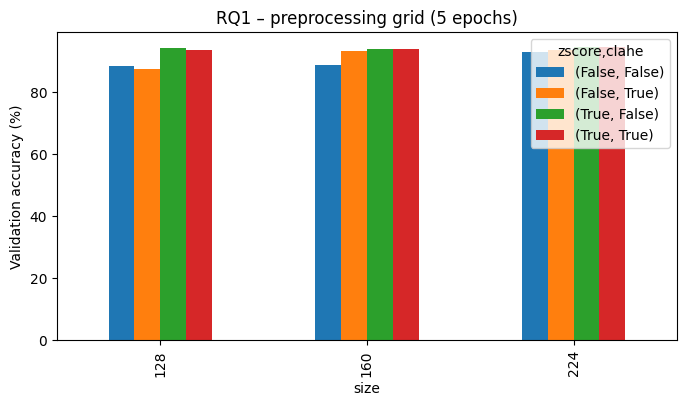

Best preprocessing combo: {'size': 224, 'zscore': True, 'clahe': True}


In [4]:
pivot = rq1_df.pivot_table(values='acc', index='size', columns=['zscore','clahe'])
pivot.plot(kind='bar', figsize=(8,4))
plt.ylabel('Validation accuracy (%)')
plt.title('RQ1 – preprocessing grid (5 epochs)')
plt.show()

best_cfg = rq1_df.iloc[0]
BEST_PREPROC = dict(size=int(best_cfg['size']),
                    zscore=bool(best_cfg['zscore']),
                    clahe=bool(best_cfg['clahe']))
print('Best preprocessing combo:', BEST_PREPROC)


## RQ2 – Augmentation × Epoch budgets

Augmentation recipes:

| key | description |
|-----|-------------|
| none | no augmentation |
| rotate15 | ±15° rotation |
| bright_contrast | brightness/contrast jitter 0.8–1.2 |
| gamma | gamma jitter 0.8–1.2 |
| flip | horizontal flip |
| crop | random‑resized crop |
| perspective | random perspective warp |
| combo | all of the above |

Each recipe is trained with **5, 10, 15, 20** epochs.


In [5]:
# ------------------------------------------------------------------
# 1) Clean helper that applies augmentation ONLY on the training set
# ------------------------------------------------------------------
def attach_transforms(exp, train_tf, val_tf):
    """
    • train_tf : full pipeline (preprocessing + augmentation)
    • val_tf   : plain preprocessing (NO augmentation)
    """
    exp.train_loader.dataset.transform = train_tf
    exp.val_loader.dataset.transform   = val_tf


# ------------------------------------------------------------------
# 2) tiny wrapper to repeat a training run several times
# ------------------------------------------------------------------
def train_repeated(exp_factory, train_tf, val_tf, epochs, n_repeats=3):
    """
    exp_factory() must return a *fresh* Experiment object.
    Returns a list of (acc, macro_F1) tuples across repeats.
    """
    acc_list, f1_list = [], []
    for r in range(n_repeats):
        exp = exp_factory()                 # new weights each repeat
        exp.set_logger(lambda *_: None)
        exp.load_data()
        exp._setup_optimizer_criterion()
        attach_transforms(exp, train_tf, val_tf)

        best_acc = 0.0
        for _ in range(epochs):
            exp._train_one_epoch()
            val_m = exp._evaluate()
            best_acc = max(best_acc, val_m['accuracy'])
        macro_f1 = exp._compute_class_metrics(val_m)['macro_f1']
        acc_list.append(best_acc)
        f1_list .append(macro_f1)
    return acc_list, f1_list


In [10]:
# Plain preprocessing (resize + optional CLAHE + z-score)
base_size = BEST_PREPROC['size']
val_tf    = build_preprocess_transform(base_size,
                                       zscore=BEST_PREPROC['zscore'],
                                       clahe =BEST_PREPROC['clahe'])
# %% [code]
# ------------------------------------------------------------------
# 1)  Additional augmentation utilities
# ------------------------------------------------------------------
import random
import torchvision.transforms.functional as F

class RandomGamma:
    """Apply a random gamma correction in the given range."""
    def __init__(self, gamma_range=(0.8, 1.2)):
        self.low, self.high = gamma_range

    def __call__(self, img):
        gamma = random.uniform(self.low, self.high)
        return F.adjust_gamma(img, gamma)

    def __repr__(self):
        return f"{self.__class__.__name__}(gamma_range=({self.low}, {self.high}))"


# ------------------------------------------------------------------
# 2)  Factory that builds ‘pre-processing + augmentation’ pipelines
# ------------------------------------------------------------------
def build_aug_transform(image_size: int,
                        base_preproc_tf: T.Compose,
                        mode: str) -> T.Compose:
    """
    Parameters
    ----------
    image_size       : final edge length (square)
    base_preproc_tf  : output of `build_preprocess_transform` (resize → tensor → z-score …)
    mode             : one of the keys in AUG_RECIPES
                       ('none', 'rotate15', 'bright_contrast', 'gamma',
                        'flip', 'crop', 'perspective', 'combo')

    Returns
    -------
    torchvision.transforms.Compose
        Pipeline that (1) applies the requested augmentation(s) on the PIL image,
        then (2) finishes with the standard preprocessing steps contained in
        `base_preproc_tf`.
    """
    aug_steps = []

    if mode in ('rotate15', 'combo'):
        aug_steps.append(T.RandomRotation(15))

    if mode in ('bright_contrast', 'combo'):
        aug_steps.append(T.ColorJitter(brightness=0.2, contrast=0.2))

    if mode in ('gamma', 'combo'):
        aug_steps.append(RandomGamma((0.8, 1.2)))

    if mode in ('flip', 'combo'):
        aug_steps.append(T.RandomHorizontalFlip())

    if mode in ('crop', 'combo'):
        # RandomResizedCrop already handles the final size
        aug_steps.append(T.RandomResizedCrop(image_size, scale=(0.8, 1.0)))

    if mode in ('perspective', 'combo'):
        aug_steps.append(T.RandomPerspective(distortion_scale=0.5, p=1.0))

    # ------------------------------------------------------------------
    # IMPORTANT: keep the *order* correct
    #   – aug_steps act on PIL images,
    #   – base_preproc_tf already contains Resize → ToTensor → optional z-score.
    # ------------------------------------------------------------------
    full_pipeline = T.Compose(aug_steps + base_preproc_tf.transforms)
    return full_pipeline

def make_train_tf(aug_mode: str) -> T.Compose:
    """
    Returns the transform to be applied on the training set
    (validation always uses `val_tf` = plain preprocessing).
    """
    if aug_mode == 'none':
        return val_tf                      # no augmentation
    else:
        return build_aug_transform(base_size, val_tf, aug_mode)



In [ ]:
N_REPEATS   = 3
AUG_RECIPES = ['none','rotate15','bright_contrast','gamma', 'crop','flip','perspective','combo']
EPOCHS_LIST = [5, 10, 15, 20]

rows = []
for aug in AUG_RECIPES:
    train_tf = make_train_tf(aug)

    for epochs in EPOCHS_LIST:
        def exp_factory():
            return Experiment(
                data_root = RAW_DATA_DIR,
                model_variant='simple',
                input_size = base_size,
                batch_size = 16,
                lr         = 1e-3,
                epochs     = epochs,
                disable_augment=True,   # we inject aug manually
                device     = DEVICE
            )

        accs, f1s = train_repeated(exp_factory, train_tf, val_tf,
                                   epochs=epochs, n_repeats=N_REPEATS)

        for a,f in zip(accs, f1s):
            rows.append(dict(aug=aug, epochs=epochs,
                             acc=a, macro_f1=f))

        print(f'{aug:12s} | {epochs:2d} ep | acc mean {np.mean(accs):.2f}%')

rq2_df = pd.DataFrame(rows)


none         |  5 ep | acc mean 90.13%
none         | 10 ep | acc mean 94.31%
none         | 15 ep | acc mean 95.35%
none         | 20 ep | acc mean 94.89%
rotate15     |  5 ep | acc mean 90.13%
rotate15     | 10 ep | acc mean 94.21%
rotate15     | 15 ep | acc mean 92.47%
rotate15     | 20 ep | acc mean 94.55%
bright_contrast |  5 ep | acc mean 93.22%
bright_contrast | 10 ep | acc mean 94.21%
bright_contrast | 15 ep | acc mean 94.70%
bright_contrast | 20 ep | acc mean 93.95%
gamma        |  5 ep | acc mean 92.45%
gamma        | 10 ep | acc mean 95.07%
gamma        | 15 ep | acc mean 94.50%
gamma        | 20 ep | acc mean 94.70%
crop         |  5 ep | acc mean 85.46%
crop         | 10 ep | acc mean 90.76%
crop         | 15 ep | acc mean 92.78%
crop         | 20 ep | acc mean 94.91%
flip         |  5 ep | acc mean 95.82%
flip         | 10 ep | acc mean 96.55%
flip         | 15 ep | acc mean 97.38%
flip         | 20 ep | acc mean 97.82%
perspective  |  5 ep | acc mean 56.31%
perspective  